# **Coin Detection, Classification, and Counting**

## Image Processing and Computer Vision - Assignment Module #1


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it


## Task & Architecture Overview

The objective of this assignment is to design and implement an end-to-end computer vision pipeline based strictly on traditional image processing techniques to:
1. **Detect** all Euro coins in heterogeneous scenes with complex backgrounds, perspective variations, and variable illumination.
2. **Classify** each detected coin into one of the 8 official Euro denominations.
3. **Compute Monetary Value** by outputting the partial sum for each image and the total grand amount across the target dataset.

---

### Engineering Choices
During our preliminary experiments, our first intuition was to rely on standard local feature matchers such as SIFT. However, we quickly observed that SIFT struggles severely on this specific task:
Euro coins have subtle 3D metallic features. Under varying illumination angles, directional shadows cast by the engravings constantly shift and deform the local gradient orientations, causing keypoint descriptors of the same coin to look drastically different across images. Furthermore, surface reflections and wear produce fragile and non-repeatable keypoints.

So we resorted to a more practical approach: after detecting the coins in the images we compared their color and relative size to find possible matches. To still leverage the coin engravings without relying on local descriptors, we decided to extract the edges, unwarp them into polar
  coordinates to create polar matrices, and match them against reference templates using circular Zero-Normalized Cross-Correlation. This gave us a kind of "fingerprint" for each coin without relying on SIFT.


### Two-Phase Pipeline Strategy

Our proposed solution is structured into two complementary phases. The first extracts all the necessary information from the given reference images in the reference set, while the second uses those information to perform the classification of the coins in the target set.

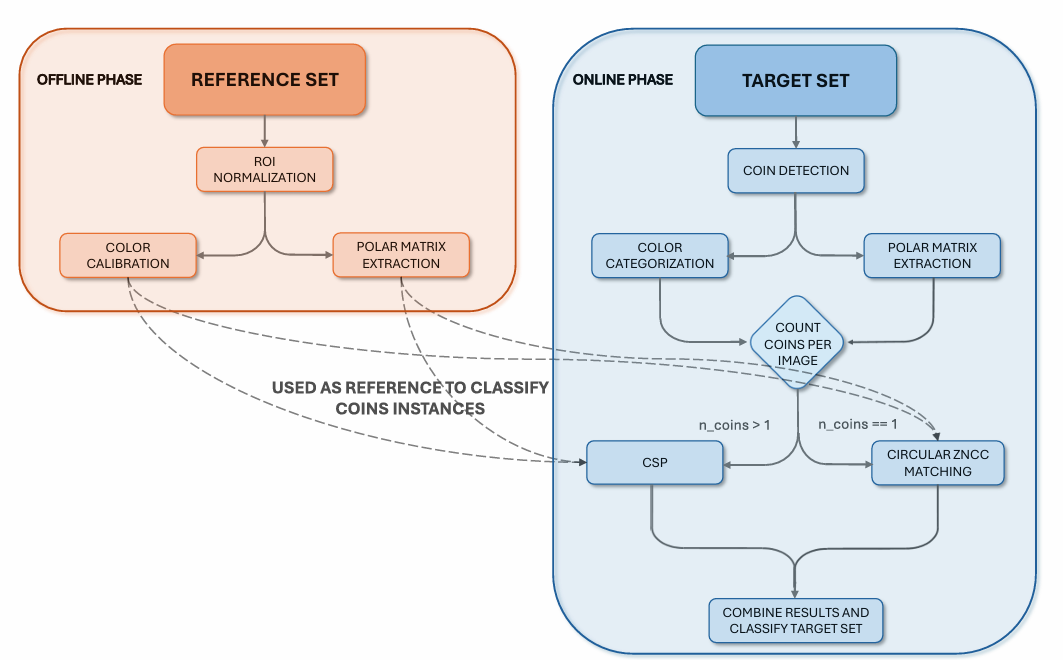


What follows is a brief description of the steps in the pipeline, each of which will be explored further in the following sections of the notebook:

1. **Offline Phase (Reference Calibration)**:
   - Normalizes ROIs (Region of Interest) of the 8 canonical reference coins to a standardized canvas ($250 \times 250$ px, $R=100$ px).
   - Calibrates the physical color boundaries: $\Delta b^*$ in CIELAB space separating bimetallic coins ($1$€ and $2$€) from single-metal coins, and median Hue in HSV under white-patch color constancy separating copper ($1$c, $2$c, $5$c) from gold ($10$c, $20$c, $50$c).
   - Generates rotation-invariant $50 \times 360$ polar templates via Canny edge detection and linear polar unwarping.


2. **Online Phase (Target Classification)**:
   - **Detection**: Image preprocessing followed by Hough Circles transform, validated by radial gradient coherence.
   - **Color Categorization**: Evaluates $\Delta b^*$ and Hue of coin instances with a continuous confidence score.
   - **Classification Branch**:
     * **Single-Coin Images**: When an image contains only one coin, we prune its candidate denominations by color group and match against the reference polar templates using circular Zero-Normalized Cross-Correlation (ZNCC) computed efficiently via FFT across all 360 angular orientations.
     * **Multi-Coin Images**: When multiple coins share the same image, they must obey physical scale consistency. We formulate an optimal assignment via a Constraint Satisfaction Problem (CSP) that takes into account the color and relative size of the detected coins as well as a dynamic ZNCC matching disambiguation.

In [ ]:

IS_COLAB = False

from pathlib import Path

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    !cp -r /content/drive/MyDrive/AssignmentsIPCV/coin_dataset.zip ./
    !unzip coin_dataset.zip
    DATASET_DIR = Path("coin_dataset")
else:
    DATASET_DIR = Path("coin_dataset")

REF_DIR = DATASET_DIR / "reference_set"
TARGET_DIR = DATASET_DIR / "target_set"



Below, we import the required libraries and define the official physical specifications of Euro coin, publicly available online.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re
import itertools
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix

# Official Euro coin diameters in millimeters
COIN_DIAMETERS = {
    "1cent": 16.25,
    "2cent": 18.75,
    "10cent": 19.75,
    "5cent": 21.25,
    "20cent": 22.25,
    "1euro": 23.25,
    "50cent": 24.25,
    "2euro": 25.75
}

# Monetary value in Euros for each denomination
COIN_VALUES = {
    "1cent": 0.01,
    "2cent": 0.02,
    "5cent": 0.05,
    "10cent": 0.10,
    "20cent": 0.20,
    "50cent": 0.50,
    "1euro": 1.00,
    "2euro": 2.00
}

# Mapping from denomination name to metallic color kind
CLASS_TO_KIND = {
    "1euro": "1 euro",
    "2euro": "2 euro",
    "10cent": "gold",
    "20cent": "gold",
    "50cent": "gold",
    "1cent": "copper",
    "2cent": "copper",
    "5cent": "copper"
}

# Color-pruned candidate denominations
KIND_TO_CANDIDATES = {
    "1 euro": ["1euro"],
    "2 euro": ["2euro"],
    "gold": ["10cent", "20cent", "50cent"],
    "copper": ["1cent", "2cent", "5cent"]
}

ORDERED_DENOMINATIONS = ["1cent", "2cent", "5cent", "10cent", "20cent", "50cent", "1euro", "2euro"]

## Offline Phase: Reference Set Processing and Calibration

In this section we describe how we process the 8 reference images to calibrate the physical properties of Euro coins:
1. **Geometric ROI Normalization**: we rescale and center each coin onto a $250 \times 250$ canvas with nominal radius of 100 px. This is necessary to later extract the polar templates.
2. **Color Calibration**: we extract from the reference coins the thresholds necessary to discriminate each coin into its "kind". The metrics are then stored for later use.
   - Bimetallic Discrimination: we measure the mean yellowness difference (CIELAB $b^*$) between outer ring of the coin and inner core of the coin:
     $$\Delta b^* = \overline{b^*}_{\text{ring}} - \overline{b^*}_{\text{centre}}$$
     where $\Delta b^* > 0$ for 1 Euro, $\Delta b^* < 0$ for 2 Euro, and $\Delta b^* \approx 0$ for monometallic coins.
   - Monometallic Discrimination (Copper vs Gold): we first normalize illuminant via White-Patch and then compute mean Hue in HSV.
3. **Rotational Polar Templates**: extract Canny edge maps and unwarp into coordinate space $(\theta, r)$ ($50 \times 360$ bins) with unit energy normalization.

The information extracted in this step (color parameters and polar templates) will be stored in appropriate variables and later confronted with those extracted from the target images during the classification process.
Below we define and explain the functions for these steps.

### Offline step 1: Reference ROI Normalization
In this step, we detect and isolate each coin from the 8 reference images, projecting them onto a canonical coordinate space.

In [ ]:

def detect_reference_circle(img_bgr: np.ndarray) -> Tuple[float, float, float]:
    """Detect the coin circle (cx, cy, radius) on a clean reference image."""

    # Convert to grayscale and blur slightly to suppress high-frequency noise
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blurred = cv2.medianBlur(gray, 7)
    
    # Run Hough Circles to find the single coin in the image
    circles = cv2.HoughCircles(
        blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100,
        param1=50, param2=30, minRadius=40, maxRadius=150
    )
    if circles is not None and len(circles[0]) > 0:
        # Take the detected coin circle
        cx, cy, r = circles[0][0]
        return float(cx), float(cy), float(r)
        
    # Fallback to image center if no circle was detected
    h, w = gray.shape
    return float(w / 2.0), float(h / 2.0), float(min(w, h) * 0.45)


def extract_normalized_roi(
    img_bgr: np.ndarray, cx: float, cy: float, radius: float,
    canvas_size: int = 250, target_radius: float = 100.0
) -> np.ndarray:
    """Extract, scale, and center the coin onto a fixed canvas with a circular mask."""
    canvas_center = canvas_size / 2.0  # 125.0 px
    scale = target_radius / radius
    
    # Simple affine transformation matrix:
    # Scale the image so the coin radius becomes target_radius and translate so coin center moves to canvas center
    T = np.float32([
        [scale, 0, canvas_center - cx * scale],
        [0, scale, canvas_center - cy * scale]
    ])
    roi = cv2.warpAffine(
        img_bgr, T, (canvas_size, canvas_size),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0)
    )
    
    # Create circular binary mask to remove table background and outer shadows
    mask = np.zeros((canvas_size, canvas_size), dtype=np.uint8)
    cv2.circle(mask, (int(canvas_center), int(canvas_center)), int(target_radius), 255, -1)
    
    # Keep only the pixels inside the coin disk
    return cv2.bitwise_and(roi, roi, mask=mask)


# Process and normalize all 8 reference images
ref_rois_bgr = {}
ref_circles = {}

for p in sorted(REF_DIR.glob("*.jpg")):
    name = p.stem
    img = cv2.imread(str(p))
    if img is not None:
        cx, cy, r = detect_reference_circle(img)
        ref_circles[name] = (cx, cy, r)
        ref_rois_bgr[name] = extract_normalized_roi(img, cx, cy, r)

print(f"Loaded and normalized {len(ref_rois_bgr)} reference coins.")

# Display the normalized reference coins in a 2x4 grid
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for idx, name in enumerate(ORDERED_DENOMINATIONS):
    ax = axes[idx]
    roi_rgb = cv2.cvtColor(ref_rois_bgr[name], cv2.COLOR_BGR2RGB)
    ax.imshow(roi_rgb)
    ax.set_title(f"{name}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Normalized Reference ROIs (250x250 px, R=100 px)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


### Offline step 2: Reference Color Calibration

In this step, we calibrate decision thresholds from the 8 clean reference coins to group denominations into macro-color categories: Bimetallic (1 euro, 2 euro), Copper (1c, 2c, 5c), and Gold (10c, 20c, 50c).

We do this in two simple stages:
1. **Bimetallic Separation (CIELAB $\Delta b^*$)**: The $b^*$ channel measures yellowness. Because 1 euro and 2 euro combine a golden alloy with silver, we compute the yellowness difference between the outer ring and the center core. A positive value indicates 1 euro, a negative value indicates 2 euro, while homogeneous single-metal coins stay close to zero.
2. **Copper vs Gold Separation (HSV Hue)**: For single-metal coins, we first apply White-Patch to balance the lighting. This is needed to ensure an illumination-invariant Hue measurement. Then, we check the average Hue: copper coins are reddish-orange (lower hue), whereas gold coins are distinctly yellow (higher hue).


We place the decision thresholds **halfway** between the reference classes and save a confidence margin. This step is important as, during classification in the Online Phase, these thresholds let us immediately prune impossible candidate denominations, while the distance from the threshold gives a continuous confidence score for uncertain colors. The color profile will then contain two important parameters: the threshold $\tau$ and the margin $\text{half\_gap}$:
- $\tau$ is computed as the midpoint between the two closest reference boundary values:
$$\tau = \frac{\max(V_{\text{class}_1}) + \min(V_{\text{class}_2})}{2}$$
- $\text{half\_gap}$ is computed as half the safety margin separating the two classes:
$$\text{half\_gap} = \frac{\min(V_{\text{class}_2}) - \max(V_{\text{class}_1})}{2}$$

Bimetallic coins and monometallic coins will both have their respective $\tau$ and $\text{half\_gap}$. The threshold will be used to discriminate between the two classes, while the margin will give the confidence of the guess.

Executing the cell below will plot these two boundaries, giving a visual interpretation on how we will classify their color during the Online phase. From the plots, we can observe that coin categories are clearly separated by their respective decision thresholds.

We also include the `confident` threshold parameter (set to 0.5) in the calibrated profiles dictionary. This value dictates how much we trust a color prediction: in this case, if a coin is less than 0.5*$\text{half\_gap}$ away from the threshold, then its color is considered uncertain. In such cases, we will avoid pruning candidate denominations prematurely, letting the geometric scale resolve potential ambiguities.


In [ ]:

def ring_minus_centre(image: np.ndarray, cx: float, cy: float, r: float) -> float:
    """
    Computes the yellowness difference (Delta b*) between the outer ring and the inner core.
    """
    # Convert image from BGR to CIELAB and extract the b* channel
    lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    b_channel = lab_image[:, :, 2].astype(np.float32)

    # Compute Euclidean distance from each pixel (x, y) to coin center (cx, cy)
    h, w = image.shape[:2]
    ys, xs = np.ogrid[:h, :w]
    distances = np.hypot(xs - cx, ys - cy)

    # Define circular regions: Core is inside 60% of radius to stay clear of the metal junction, while
    # Ring is between 80% and 90% of radius to avoid the outer rim
    core_mask = distances < (0.6 * r)
    ring_mask = (distances >= 0.8 * r) & (distances < 0.9 * r)

    # Calculate average yellowness in both regions and return their difference
    mean_ring_yellowness = float(b_channel[ring_mask].mean())
    mean_core_yellowness = float(b_channel[core_mask].mean())
    return mean_ring_yellowness - mean_core_yellowness


def white_patch(image: np.ndarray) -> np.ndarray:
    """
    Applies White-Patch Retinex to remove the color cast of the scene illuminant.
    """
    # Find the 99th percentile brightness per color channel
    brightest = np.percentile(image, 99, axis=(0, 1))
    
    # Avoid division by zero if an image channel is completely dark
    brightest = np.where(brightest == 0, 1.0, brightest)
    
    # Scale channels to [0, 255] and convert back to uint8
    normalized = (image / brightest) * 255.0
    return np.clip(normalized, 0, 255).astype(np.uint8)


def coin_hue(image: np.ndarray, cx: float, cy: float, r: float) -> float:
    """
    Computes the average Hue angle in degrees (0 - 360) inside the coin.
    """
    # Create a mask for the coin interior
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    cv2.circle(mask, (round(cx), round(cy)), round(0.9 * r), 255, -1)

    # Convert normalized image to float HSV so OpenCV returns Hue in degrees [0, 360]
    hsv_image = cv2.cvtColor(image.astype(np.float32) / 255.0, cv2.COLOR_BGR2HSV)
    hue_channel = hsv_image[:, :, 0]

    # Select only the hue values inside the coin mask
    coin_hues = hue_channel[mask > 0]

    # Hue is circular around 0°. Since deep reds can wrap around above 180°
    # (e.g. 350° is equivalent to -10°), we map them to negative values to compute a proper average
    coin_hues = np.where(coin_hues > 180, coin_hues - 360, coin_hues)
    return float(coin_hues.mean())



# Here we Calibrate the Thresholds for the Bimetallic Reference Coins

ref_deltas = {}
for name, (cx, cy, r) in ref_circles.items():
    orig_img = cv2.imread(str(REF_DIR / f"{name}.jpg"))
    ref_deltas[name] = ring_minus_centre(orig_img, cx, cy, r)

# Single-metal coins should have near-zero Delta b*, while 1 euro and 2 euro have large values
single_deltas = [abs(ref_deltas[n]) for n in ref_deltas if n not in ("1euro", "2euro")]
largest_single_delta = max(single_deltas)

bimetal_deltas = [abs(ref_deltas["1euro"]), abs(ref_deltas["2euro"])]
smallest_bimetal_delta = min(bimetal_deltas)

# Place threshold tau halfway between single-metal and bimetallic references
tau_bimetal = (largest_single_delta + smallest_bimetal_delta) / 2.0
bimetal_half_gap = (smallest_bimetal_delta - largest_single_delta) / 2.0



# Here we Calibrate Copper vs Gold Hue Threshold from Monometallic References

ref_hues = {}
single_metal_names = [n for n in ref_circles if n not in ("1euro", "2euro")]

for name in single_metal_names:
    cx, cy, r = ref_circles[name]
    orig_img = cv2.imread(str(REF_DIR / f"{name}.jpg"))
    # Apply White-Patch color balancing first
    wp_img = white_patch(orig_img)
    ref_hues[name] = coin_hue(wp_img, cx, cy, r)

# Copper is reddish (lower hue), Gold is yellow (higher hue)
copper_hues = [ref_hues["1cent"], ref_hues["2cent"], ref_hues["5cent"]]
gold_hues = [ref_hues["10cent"], ref_hues["20cent"], ref_hues["50cent"]]
most_yellow_copper_hue = max(copper_hues)
least_yellow_gold_hue = min(gold_hues)

# Place threshold tau halfway between the two groups
tau_hue = (most_yellow_copper_hue + least_yellow_gold_hue) / 2.0
hue_half_gap = (least_yellow_gold_hue - most_yellow_copper_hue) / 2.0


# Store calibrated parameters for use in the Online Phase
color_profiles = {
    "bimetal": {"threshold": tau_bimetal, "half_gap": bimetal_half_gap, "confident": 0.5},
    "single_metal": {"threshold": tau_hue, "half_gap": hue_half_gap, "confident": 0.5}
}

print(f"Bimetallic threshold (Delta b*): {tau_bimetal:.2f} (half-gap: {bimetal_half_gap:.2f})")
print(f"Copper vs Gold threshold (Hue):   {tau_hue:.1f}° (half-gap: {hue_half_gap:.1f}°)")



# Here we plot Calibration Distributions for Visual Verification

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Delta b* (Bimetallic separation)
names_b = sorted(ref_deltas.keys(), key=ref_deltas.get)
colors_b = ["#1f77b4" if n in ("1euro", "2euro") else "#7f7f7f" for n in names_b]
bars1 = ax1.bar(names_b, [ref_deltas[n] for n in names_b], color=colors_b, edgecolor="black", alpha=0.85)
ax1.bar_label(bars1, labels=[f"{ref_deltas[n]:+.1f}" for n in names_b], fontsize=9, fontweight="bold")
ax1.axhline(tau_bimetal, color="red", linestyle="--", linewidth=1.5, label=f"+tau (+{tau_bimetal:.2f}) -> 1 euro")
ax1.axhline(-tau_bimetal, color="blue", linestyle="--", linewidth=1.5, label=f"-tau (-{tau_bimetal:.2f}) -> 2 euro")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_title("1. Bimetallic vs Monometallic (CIELAB Delta b*)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Delta b* (Ring - Core)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left")

# Subplot 2: White-Patch HSV Hue (Copper vs Nordic Gold separation)
names_h = sorted(ref_hues.keys(), key=ref_hues.get)
colors_h = ["#d95f02" if n in ("1cent", "2cent", "5cent") else "#e6ab02" for n in names_h]
bars2 = ax2.bar(names_h, [ref_hues[n] for n in names_h], color=colors_h, edgecolor="black", alpha=0.85)
ax2.bar_label(bars2, labels=[f"{ref_hues[n]:.1f}°" for n in names_h], fontsize=9, fontweight="bold")
ax2.axhline(tau_hue, color="green", linestyle="--", linewidth=1.5, label=f"tau ({tau_hue:.1f}°) -> Copper/Gold")
ax2.set_title("2. Copper vs Gold (White-Patch HSV Hue)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Hue (Degrees)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()


### Offline step 3: Edge Extraction and Polar Templates

To distinguish coins belonging to the same color class, we analyze the physical engravings on their surface. As anticipated, local keypoint detectors like SIFT perform poorly on metallic surfaces because of directional reflections in different light conditions. We instead rely on the structural contours of the reliefs.

We enhance the normalized coin with CLAHE to balance local contrast and apply a bilateral filter to suppress metallic grain without blurring the engraving boundaries. After extracting edges via Canny, we remove the outer circular rim because every coin has an identical circular perimeter, and we want to keep only the internal features.

Because coins in target images will appear with arbitrary orientations, comparing them directly in Cartesian coordinates would require rotating the 2D template at every possible angle. To solve this, we unwarp the edge image into polar coordinates $(r, \theta)$ on a $50 \times 360$ grid. In polar space, any planar rotation turns into a simple horizontal shift along the angular axis, allowing fast matching via circular cross-correlation. Finally, a gentle Gaussian blur slightly thickens the edges, making the template tolerant to sensor noise and small perspective misalignments.

Note that the parameters in `REF_EDGE_PARAMS` were tweaked manually, in order to obtain the cleanest extraction of the edges from the reference image, by visually inspecting the results. Since this was a preprocessing step on the reference set, we could afford to use different parameters for each of the 8 coins. Obviously, later in the Online phase, this step will be automated as every coin will undergo the same treatment, where the optimal edge extraction will be guaranteed by "autocanny", an algorithm that dynamically optimizes the canny parameters to obtain the best results. Furthermore, we found out that grouping individual edge pixels into bins (50 in this case) yielded the best results during experimentation, most probably because it adds another layer of tolerance to single-pixel misalignments.

From the output of the cell below, we can clearly see how the macro-features of the coins (for example the number 5 in the 5-cent coin) are clearly preserved in their respective polar matrices.

Note: our decision to avoid local keypoint descriptors and instead rely on edge-based polar unwarping and circular correlation was partially inspired by these two papers in computer vision literature for coin analysis:

**Chen (2010)** [*Chinese Coin Recognition Based on Unwrapped Image and Rotation Invariant Template Matching*].

**Reisert et al. (2006)** [*An Efficient Gradient Based Registration Technique for Coin Recognition*].

In [ ]:
# Canny and Bilateral filter parameters tuned for each reference coin
REF_EDGE_PARAMS = {
    "10cent": {"d": 1, "sigma": 30, "t1": 65, "t2": 250},
    "1cent":  {"d": 5, "sigma": 80, "t1": 70, "t2": 35},
    "1euro":  {"d": 7, "sigma": 85, "t1": 50, "t2": 70},
    "20cent": {"d": 7, "sigma": 70, "t1": 60, "t2": 150},
    "2cent":  {"d": 7, "sigma": 55, "t1": 25, "t2": 65},
    "2euro":  {"d": 7, "sigma": 90, "t1": 30, "t2": 70},
    "50cent": {"d": 7, "sigma": 75, "t1": 60, "t2": 95},
    "5cent":  {"d": 7, "sigma": 80, "t1": 35, "t2": 70}
}


def extract_reference_edge(gray_roi: np.ndarray, params: Dict[str, Any]) -> np.ndarray:
    """
    Extracts coin relief edges from a normalized ROI.
    """
    # Enhance local contrast with CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray_roi)

    #  Bilateral Filter
    d = params.get("d", 7)
    sigma = float(params.get("sigma", 75.0))
    smoothed = cv2.bilateralFilter(enhanced, d=d, sigmaColor=sigma, sigmaSpace=sigma) if d > 0 else enhanced

    # Detect relief edges using Canny with coin-specific thresholds
    t1, t2 = int(params.get("t1", 50)), int(params.get("t2", 140))
    edges = cv2.Canny(smoothed, t1, t2)

    # Remove outer circular outer rim
    h, w = edges.shape[:2]
    ys, xs = np.ogrid[:h, :w]
    circle_mask = np.hypot(xs - 125.0, ys - 125.0) <= 99.0
    edges[~circle_mask] = 0

    return edges


def compute_polar_unwarp(
    edge_img: np.ndarray,
    center: Tuple[float, float] = (125.0, 125.0),
    max_radius: float = 100.0,
    dims: Tuple[int, int] = (50, 360),
    blur_ksize: Tuple[int, int] = (5, 5),
    normalize_energy: bool = True
) -> np.ndarray:
    """
    Unwarps a 250x250 circular edge map into a polar matrix (50 radial bins x 360 angle bins).
    """
    rad_bins, ang_bins = dims

    # Apply a mild Gaussian blur to slightly thicken edges
    blurred = cv2.GaussianBlur(edge_img, blur_ksize, 0) if (blur_ksize and blur_ksize[0] > 0) else edge_img.copy()

    #Linear polar unwarp
    polar_full = cv2.warpPolar(
        blurred, (int(max_radius), int(ang_bins)), center, max_radius,
        cv2.WARP_POLAR_LINEAR + cv2.INTER_LINEAR + cv2.WARP_FILL_OUTLIERS
    )

    #Downsample to target radial bins
    if polar_full.shape[1] != rad_bins:
        polar_matrix = cv2.resize(polar_full, (rad_bins, ang_bins), interpolation=cv2.INTER_AREA)
    else:
        polar_matrix = polar_full

    # Transpose so rows = radius r and columns = angle theta
    polar_matrix = polar_matrix.T.astype(np.float32)

    # Normalize total energy so templates with different edge counts are directly comparable
    if normalize_energy:
        total = float(np.sum(polar_matrix))
        if total > 0:
            polar_matrix /= total

    return polar_matrix



#Process and Build Polar Templates for All 8 Reference Coins
ref_edges = {}
ref_polar_templates = {}

for name in ORDERED_DENOMINATIONS:
    roi_gray = cv2.cvtColor(ref_rois_bgr[name], cv2.COLOR_BGR2GRAY)
    edges = extract_reference_edge(roi_gray, REF_EDGE_PARAMS[name])
    ref_edges[name] = edges
    ref_polar_templates[name] = compute_polar_unwarp(edges)

print(f"Generated {len(ref_polar_templates)} reference polar templates.")



# Example on the 5-Cent Reference Coin

fig_ex, (ax_edge, ax_polar) = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Extracted Cartesian Canny edges
ax_edge.imshow(ref_edges["5cent"], cmap="gray")
ax_edge.set_title("5 Cent - Extracted Relief Edges", fontsize=11, fontweight="bold")
ax_edge.axis("off")

# Subplot 2: Unwarped Polar matrix
im_ex = ax_polar.imshow(
    ref_polar_templates["5cent"],
    aspect="auto",
    cmap="viridis",
    origin="lower",
    extent=[0, 360, 0, 50]
)
ax_polar.set_title("5 Cent - Polar Unwarp Matrix", fontsize=11, fontweight="bold")
ax_polar.set_xlabel("Angle θ (degrees: 0° - 360°)")
ax_polar.set_ylabel("Radius r (bins: 0 - 50)")
fig_ex.colorbar(im_ex, ax=ax_polar, fraction=0.046, pad=0.04)

plt.suptitle("Example of Polar Unwarping: 5-Cent Reference Coin", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



# Complete Set of Reference Polar Templates

fig_all, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for idx, name in enumerate(ORDERED_DENOMINATIONS):
    ax = axes[idx]
    mat = ref_polar_templates[name]
    ax.imshow(mat, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 0, 50])
    ax.set_title(f"Reference: {name}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Angle θ (0° - 360°)")
    ax.set_ylabel("Radius r (0 - 50)")

plt.suptitle("Complete Set of Reference Polar Templates", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## Online Phase: Target Classification

This is the phase of the pipeline that directly classifies all the instances of the coins found in the images of the target set, and computes the total monetary value.
In this section we will define all detection, feature extraction, and classification steps. Here is a brief summary of the role of each component of this phase:
1. **Coin detection**: Similar to what we did for the reference images, this component is responsible of finding the correct instances of each coin in an image, by locating its coordinates and radius using Hough Gradient circle detection.
2. **Color Categorization**: This step computes $\Delta b^*$ and White-Patch Hue on each of the coins, returning the estimated macro-group (that we named `kind`), as well as a confidence score.
3. **Polar Matrix Extraction**: For each of the detected coin an edge map is extracted using an adaptive version of the Canny algorithm. This is then transformed into a polar matrix so that it can be later compared with those of the reference images via Zero-Normalized Cross-Correlation.
4. **Coin Classification**:  We assign the final denomination to each coin using this strategy: When only one coin is present, we just rely on color group pruning and direct polar template matching (ZNCC) to pick the best-matching denomination. When instead there are multiple coins in an image, we leverage relative scale consistency across the coins using a CSP algorithm. The algorithm finds the combination of denominations that best respects both the expected color groups and the physical diameter proportions between coins, using polar template matching primarily to resolve ambiguous denominations.

The decision to split the main classification algorithm into two was due to two simple factors that emerged during experimentation: during our initial tests, we observed that combining color pruning with polar template matching produced acceptable baseline results. However, this technique was quite error-prone. At the same time, we noticed that the vast majority of the target dataset consists of scenes with multiple coins, which provides a crucial piece of information, i.e. their relative sizes. Analyzing relative diameter ratios proved to be vastly more reliable and stable than relying on surface reliefs alone. Ignoring this geometric constraint would mean throwing away the most informative feature in the images. So we decided to combine both approaches, and this proved to be successful.

### Preliminary Data Inspection

When inspecting the target images, we noticed that, in addition to real-world complex conditions, such as background textures and uneven lighting, every picture was subject to synthetic noise injection. In particular, we observed salt-and-pepper noise across the RGB channels (visible as isolated pixels of contrasting colors) as well as a Gaussian noise grain. Furthermore, the coins in the images appeared kind of bluish, indicating that the red and blue color channels had probably been swapped.

We will address these distortions in different ways at every step of the Online Phase.
We plot below some examples to get an idea of the distortion to the target images.

In [ ]:
# Display two random target images to visually inspect the injected noise and swapped channels
target_image_paths = sorted(list(TARGET_DIR.glob("*.jpg")))
sample_paths = np.random.choice(target_image_paths, size=2, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img_path in zip(axes, sample_paths):
    raw_bgr = cv2.imread(str(img_path))
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    
    ax.imshow(raw_rgb)
    ax.set_title(f"{img_path.name}", fontsize=11, fontweight="bold")

plt.suptitle("Target Set Noise example", fontsize=13)
plt.tight_layout()
plt.show()

### Online phase step 1: Coin Detection

The first step in the online phase consists in accurately locating all Euro coins in the images. To achieve reliable detection, we divide this step into three stages: noise preprocessing, circle detection via Hough Transform, and radial gradient validation.

For the stage of coin detection we used the following technique to denoise:
1. We convert the image to CIELAB and isolate the luminance channel ($L^*$).
2. We apply a $3 \times 3$ median filter.
3. We apply a strong Non-Local Means denoising.
4. We apply a Gaussian blur ($11 \times 11$).
5. Finally, we apply CLAHE.

This specific combination of filters and their parameters were mostly found to work well through trial and error and inspection onf the result, but the key concepts that brought us to try this sequence were all grounded into the properties we learned during the lectures. We converted to CIELAB rather than gray scale because working on lightness removes chromatic distractions because some pixels in different channels could be perceived more intense than others. The median filter mainly removes salt and pepper noise, while NLMeans smooths gaussian noise while still preserving the edges of the coins. Then a gaussian blur ensures that edge detection responds to macro coin boundaries rather than minor details inside the coins, and finally CLAHE restores and amplifies local contrast along coin perimeters after smoothing all other noise.

For the detection part we decided to detect circular candidates using the Hough Gradient transform (`cv2.HOUGH_GRADIENT`). As before, we deliberately tuned each parameter based on our trials and the physical setup. For example:
* Minimum distance between centers set to 100 (`minDist = 100`) because it prevents finding duplicate or concentric circles for the same coin.
* Search radius bounds (`minRadius = 50, maxRadius = 130`) because it restricts detection strictly to the plausible physical range of coin sizes across the target images.
* Other parameters, such as the thresholds, were the results of trial and error.

Finally, since we went for a really sensitive Hough threshold, we found that it triggered a lot of false positives on rounded background features. These did not impact too much the accuracy of the classification, but they significantly increased the total computed amount, since all these false positives added up to a substantial amount of euros. To deal with this, we decided to use an additional technique of radial gradient validation. To do so, we validate each candidate found using an intuitive physical observation: along the perimeter of a genuine coin, the image gradient must be perpendicular to the circular boundary. So we sample 72 points along the circumference of each candidate and compute the alignment between the Sobel image gradient and the radial direction, weighting the score by gradient magnitude. Genuine coins show strong, consistent radial gradient support along almost their entire circumference, yielding a high enough score (that we found to be $\ge 0.85$). Spurious background patterns, which only align with the radius at isolated random angles, are instead reliably rejected.

Below we show an example of the detection on sample random images.

In [ ]:

@dataclass(frozen=True)
class Circle:
    cx: float
    cy: float
    radius: float


def preprocess_for_detection(image: np.ndarray) -> np.ndarray:
    """
    Preprocesses the image to eliminate noise and enhance coin circular boundaries.
    """
    # Convert to CIELAB and extract L* channel
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)[:, :, 0]

    # Light median blur
    gray = cv2.medianBlur(gray, 3)

    # Non-Local Means (NLM)
    gray = cv2.fastNlMeansDenoising(gray, h=45.0, templateWindowSize=7, searchWindowSize=21)

    # Gaussian blur
    gray = cv2.GaussianBlur(gray, (11, 11), 0)

    # CLAHE
    clahe = cv2.createCLAHE(clipLimit=1.2, tileGridSize=(16, 16))
    return clahe.apply(gray)


def detect_circles_hough(
    preprocessed: np.ndarray,
    dp: float = 1.3,
    min_dist: float = 100.0,
    param1: float = 50.0,
    param2: float = 30.0,
    min_radius: int = 50,
    max_radius: int = 130
) -> List[Circle]:
    """
    Detects circle candidates using the Hough Gradient transform.
    """
    circles = cv2.HoughCircles(
        preprocessed, cv2.HOUGH_GRADIENT,
        dp=dp, minDist=min_dist, param1=param1, param2=param2,
        minRadius=min_radius, maxRadius=max_radius
    )
    if circles is None:
        return []

    return [Circle(float(cx), float(cy), float(r)) for cx, cy, r in circles[0]]


def filter_by_edge_support(
    gray: np.ndarray,
    circles: List[Circle],
    min_score: float = 0.85,
    n_samples: int = 72
) -> List[Circle]:
    """
    Validates candidates by checking if the Sobel gradients along the circumference
    point in the radial direction. Real coins have score >= 0.85.
    """
    if not circles:
        return []

    # Compute horizontal and vertical image gradients using Sobel
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    angle = np.arctan2(gy, gx)
    h, w = mag.shape

    # Precompute 72 sample angles along a full circle
    thetas = np.linspace(0, 2 * np.pi, n_samples, endpoint=False)
    cos_t, sin_t = np.cos(thetas), np.sin(thetas)

    valid_circles = []
    for c in circles:
        # Sample points along the circumference
        xs = np.clip(np.round(c.cx + c.radius * cos_t).astype(int), 0, w - 1)
        ys = np.clip(np.round(c.cy + c.radius * sin_t).astype(int), 0, h - 1)

        mags = mag[ys, xs]
        angles = angle[ys, xs]

        # Theoretical radial direction pointing outward from circle center
        radial_angles = np.arctan2(ys - c.cy, xs - c.cx)

        # Measure alignment: cos^2 of angular difference is 1 when gradients point radially
        diff = np.abs(angles - radial_angles) % np.pi
        alignment = np.cos(diff) ** 2

        # Magnitude-weighted alignment score
        total_mag = mags.sum()
        score = float(np.sum(alignment * mags) / total_mag) if total_mag > 1e-8 else 0.0

        if score >= min_score:
            valid_circles.append(c)

    return valid_circles


def detect_coins_in_image(img_bgr: np.ndarray) -> List[Circle]:
    """
    Returns detected coins.
    """
    prep = preprocess_for_detection(img_bgr)
    candidates = detect_circles_hough(prep)
    return filter_by_edge_support(prep, candidates, min_score=0.85)



#Visual example
np.random.seed(42)
sample_paths = np.random.choice(sorted(list(TARGET_DIR.glob("*.jpg"))), size=2, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img_path in zip(axes, sample_paths):
    img = cv2.imread(str(img_path))
    detected = detect_coins_in_image(img)

    # Draw detected circles
    vis = img.copy()
    for c in detected:
        cv2.circle(vis, (int(c.cx), int(c.cy)), int(c.radius), (0, 255, 0), 3)
        cv2.circle(vis, (int(c.cx), int(c.cy)), 5, (0, 0, 255), -1)

    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{img_path.name} ({len(detected)} coin(s) detected)", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Coin Detection Output on Sample Images", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

### Online phase step 2: Color Categorization

Once coin circles are detected, the next step is categorizing each coin into one of four macro-color groups: **1 Euro**, **2 Euro**, **copper** (1c, 2c, 5c), or **gold** (10c, 20c, 50c). Grouping coins by metal composition is fundamental since it will significantly prune the search space before running classification in the later stages.

Firstly, as stated during our preliminary data inspection, images in the target set have inverted Red and Blue color channels. So we swap them prior to any color feature extraction.
Then we run each coin into a very simple decision tree: we first check if the coin is bimetallic (by comparing its $\Delta b^*$ with those extracted during the offline phase). If it is, we classify its kind either as 1 euro or 2 euros, otherwise we will analyze it as a monometallic coin. In the latter case we first apply White-Patch Retinex to deal with scene illumination. We then evaluate the average Hue in HSV: copper coins show reddish-orange hues, whereas gold coins show higher yellowish hues. The hues extracted are again compared with those stored from the offline phase.

  In both cases we calculate a continuous confidence score measuring the normalized distance of the metric extracted to its reference threshold. If confidence is $\ge 0.5$ (as calibrated during the Offline phase), the group is marked as reliable (`confident = True`), else the coin is flagged as uncertain, allowing subsequent classification steps to relax candidate pruning. We devised the confidence score ($conf \in [0.0, 1.0]$) to be computed based on the values of the threshold $\tau$ and the margin ${\text{half\_gap}}$ found during calibration:

$$\text{confidence} = \min\left( \frac{|\text{observed\_value} - \tau|}{\text{half\_gap}}, 1.0 \right)$$

A coin landing directly on the decision boundary yields a confidence of $0.0$ (maximum ambiguity), whereas a coin lying at or beyond the expected reference margin reaches $1.0$ (maximum certainty).

In the following code, in case of bimetallic coins, the half_gap is `b_gap`, while for monometallic coins it's `h_gap`. Both of these had been extracted earlier during the color calibration step. Note that, for single-metal coins, the final confidence is defined as:
$$conf = \min(b\_conf, h\_conf)$$

This is because, to be truly confident that a coin belongs to a single-metal class, two conditions must hold simultaneously:
1. It must be confidently non-bimetallic ($b\_conf$ is high, meaning $|\Delta b^*|$ is well below $\tau_{\text{bimetal}}$).
2. Its Hue must unambiguously match its kind ($h\_conf$ is high).

Below we plot two examples, one for low confidence coin and one for a high confidence coin.


In [ ]:

def classify_coin_color(
    img_color: np.ndarray,
    img_wp: np.ndarray,
    cx: float, cy: float, r: float,
    profiles: Dict[str, Any]
) -> Dict[str, Any]:
    """
    Classifies a detected coin into one of 4 macro-color groups (1 euro, 2 euro, gold, copper)
    along with a continuous confidence score.
    """
    # Check bimetallic yellowness difference (ring minus centre in CIELAB)
    b_thr = profiles["bimetal"]["threshold"]
    b_gap = profiles["bimetal"]["half_gap"]
    delta = ring_minus_centre(img_color, cx, cy, r)
    b_conf = min(abs(abs(delta) - b_thr) / b_gap, 1.0)

    if delta > b_thr:
        kind = "1 euro"
        conf = b_conf
    elif delta < -b_thr:
        kind = "2 euro"
        conf = b_conf
    else:
        # For single-metal coins, evaluate Hue
        h_thr = profiles["single_metal"]["threshold"]
        h_gap = profiles["single_metal"]["half_gap"]
        hue = coin_hue(img_wp, cx, cy, r)
        h_conf = min(abs(hue - h_thr) / h_gap, 1.0)
        kind = "gold" if hue > h_thr else "copper"
        conf = min(b_conf, h_conf)

    return {
        "kind": kind,
        "confidence": round(conf, 2),
        "confident": bool(conf >= 0.5)
    }



# Visual example on 2 sample target images
sample_names = ["image_114.jpg", "image_116.jpg"]
sample_paths = [TARGET_DIR / s for s in sample_names if (TARGET_DIR / s).exists()]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img_path in zip(axes, sample_paths):
    raw_bgr = cv2.imread(str(img_path))
    coins = detect_coins_in_image(raw_bgr)

    # Realign swapped R/B channels on target image
    img_color = cv2.cvtColor(raw_bgr, cv2.COLOR_RGB2BGR)
    img_wp = white_patch(img_color)

    vis = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
    for c in coins:
        col = classify_coin_color(img_color, img_wp, c.cx, c.cy, c.radius, color_profiles)
        cv2.circle(vis, (int(c.cx), int(c.cy)), int(c.radius), (0, 255, 0), 3)
        label = f"{col['kind']} ({col['confidence']})"
        cv2.putText(vis, label, (int(c.cx - c.radius), int(c.cy - c.radius - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 0), 2)

    ax.imshow(vis)
    ax.set_title(f"{img_path.name} - Color Categorization", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Online Step 2: Coin Color Categorization Examples", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

### Online phase step 3: Target Edge Extraction and Polar Unwarping

To capture the features of the coins in the target images, we extract their contours and transform them into a normalized polar representation matching the reference templates generated in the offline phase.


As before, each detected coin disc is extracted and affine-warped onto a fixed $250 \times 250$ pixel canvas with a radius of 100 pixels. This isolates the coin and removes perspective scale differences. We then want to extract the edge maps from the isolated coins, but the variety of conditions in the target set posed a problem: if we used a fixed way to extract the edges we would detect a very different amount of edge pixels from coin to coin, because there are images in which the contrast is very clear, while others appear almost flat.

To solve this we implemented a way to have an Adaptive Thresholding for the Canny algorithm, using what is known as *Auto-Canny*: we analyze the statistical distribution of Sobel gradient magnitudes inside the coin disc and adaptively set $T_1$ and $T_2$ to the 75th and 92nd percentiles. Furthermore, we dynamically verify the total count of detected edge pixels: if edges are too dense ($> 2800$ pixels), thresholds are automatically tightened; if too sparse ($< 800$ pixels), thresholds are relaxed to recover faint engravings. We found the values for the adaptive threshold by inspecting their effect on samples of the target set, while the constraint on the number of pixels was based on the number of pixels of edge maps from the reference set.

Then, we continue by eliminating pixels located at the outer circular boundary of the coin, as we did for the reference set.

Finally, we compute and store the polar matrix of each coin the same way we did for the reference set.

Once we have the polar edge representation, we will need a way to compare the target coin against our reference templates to recognize its features.

To find the optimal rotational alignment and measure structural similarity, we define the `compute_circular_zncc` function which computes the Zero-Normalized Cross-Correlation (ZNCC) across all 360 possible angular shifts $\Delta \theta$, using the 1D Fast Fourier Transform (FFT) along the angular axis for computational efficiency. The final score is the maximum correlation across all shifts:

$$\text{ZNCC}_{\max}(T, R) = \max_{\Delta \theta} \frac{\sum_{r, \theta} \big(T(r, \theta + \Delta \theta) - \mu_T\big)\big(R(r, \theta) - \mu_R\big)}{N \cdot \sigma_T \cdot \sigma_R}$$

where $\mu$ and $\sigma$ are the mean and standard deviation of the matrices, and $N$ is the total number of elements. This produces a rotation-invariant similarity score between $-1$ and $+1$, where higher values indicate an accurate match with the reference coin.

Before edge extraction, though, we have to address the noise. So we apply CLAHE to boost the local contrast of faint engravings, and then we apply a Bilateral Filter to suppress gaussian noise while strictly preserving sharp edges for Canny.

As for all the other steps, there are many ways to implement this kind of solutions, but through various experimentation we found that this combination of preprocessing, edge extraction and comparison via ZNCC was the closest to achieving the results we were looking for.


In [ ]:

def extract_target_coin_edge_map(
    img_bgr: np.ndarray,
    cx: float, cy: float, radius: float,
    canvas_size: int = 250, target_radius: float = 100.0
) -> np.ndarray:
    """
    Extracts coin edges using adaptive Auto-Canny thresholding.
    """
    # Affine warp to center and rescale coin onto a fixed 250x250 canvas with radius 100
    center = canvas_size / 2.0
    scale = target_radius / max(radius, 1.0)
    T = np.float32([
        [scale, 0, center - cx * scale],
        [0, scale, center - cy * scale]
    ])
    roi_bgr = cv2.warpAffine(
        img_bgr, T, (canvas_size, canvas_size),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0)
    )
    roi_gray = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)

    # Local contrast enhancement and bilateral filtering to smooth metallic grain
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_proc = clahe.apply(roi_gray)
    img_proc = cv2.bilateralFilter(img_proc, d=7, sigmaColor=75.0, sigmaSpace=75.0)

    #Mask interior coin disc
    yy, xx = np.ogrid[:canvas_size, :canvas_size]
    mask_outside = ((xx - center) ** 2 + (yy - center) ** 2) > ((target_radius - 1.0) ** 2)
    mask_inside = ~mask_outside

    #Auto-Canny: adapt thresholds dynamically based on gradient magnitude percentiles
    gx = cv2.Sobel(img_proc, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_proc, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    vals = mag[mask_inside]

    t1 = int(max(25, np.percentile(vals, 75.0)))
    t2 = int(max(t1 + 25, np.percentile(vals, 92.0)))
    edge_img = cv2.Canny(img_proc, t1, t2)
    edge_img[mask_outside] = 0

    # Dynamic density adjustment if edges are oversaturated or too sparse
    cnt = int(np.count_nonzero(edge_img))
    if cnt > 2800:
        t1 = int(max(30, np.percentile(vals, 82.0)))
        t2 = int(max(t1 + 30, np.percentile(vals, 95.0)))
        edge_img = cv2.Canny(img_proc, t1, t2)
        edge_img[mask_outside] = 0
    elif cnt < 800:
        t1 = int(max(18, np.percentile(vals, 65.0)))
        t2 = int(max(t1 + 20, np.percentile(vals, 85.0)))
        edge_img = cv2.Canny(img_proc, t1, t2)
        edge_img[mask_outside] = 0

    return edge_img


def compute_circular_zncc(target: np.ndarray, reference: np.ndarray) -> Tuple[float, int]:
    """
    Computes rotation-invariant Zero-Normalized Cross-Correlation (ZNCC) between two polar matrices.
    .
    """
    #Compute means and standard deviations for zero-normalization
    t_mean, r_mean = target.mean(), reference.mean()
    t_std, r_std = target.std(), reference.std()
    
    # Denominator for ZNCC: N * sigma_T * sigma_R
    denom = t_std * r_std * target.size
    if denom < 1e-12:
        # If one of the templates has zero variance (no edges detected), correlation is undefined
        return 0.0, 0

    # Subtract mean from both templates to make the correlation invariant to brightness offsets
    t_norm = target - t_mean
    r_norm = reference - r_mean

    # Fast Circular Cross-Correlation via 1D FFT along the angular dimension (axis=1)
    # By the Correlation Theorem: corr(x, y) = IFFT(FFT(x) * conj(FFT(y)))
    F_t = np.fft.fft(t_norm, axis=1)
    F_r = np.fft.fft(r_norm, axis=1)
    
    # Multiply F_t by the complex conjugate of F_r and invert back to the spatial domain
    corr_per_r = np.fft.ifft(F_t * np.conj(F_r), axis=1).real

    # Sum correlation across all radial bands and normalize by the standard deviations
    # This yields the ZNCC score for each of the 360 possible angular shifts (0 to 359 degrees)
    corr_profile = np.sum(corr_per_r, axis=0) / denom

    # Find the optimal angular alignment and highest correlation score
    best_shift = int(np.argmax(corr_profile))
    best_score = float(corr_profile[best_shift])

    return best_score, best_shift



# Visual example
sample_img = cv2.imread(str(TARGET_DIR / "image_1.jpg"))
detected_coins = detect_coins_in_image(sample_img)
sample_c = detected_coins[0]

# Extract edges and compute polar matrix
sample_edge_map = extract_target_coin_edge_map(sample_img, sample_c.cx, sample_c.cy, sample_c.radius)
sample_polar_mat = compute_polar_unwarp(sample_edge_map, dims=(50, 360))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.imshow(sample_edge_map, cmap="gray")
ax1.set_title("Target Coin - Auto-Canny Edges", fontsize=11, fontweight="bold")
ax1.axis("off")

im = ax2.imshow(sample_polar_mat, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 0, 50])
ax2.set_title("Target Coin - Unwarped Polar Matrix (r vs θ)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Angle θ (degrees: 0° - 360°)")
ax2.set_ylabel("Radius r (bins: 0 - 50)")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

plt.suptitle("Online Step 3: Target Edge Extraction and Polar Unwarping Example", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

### Online phase step 4: Coin Classification

In this final step, we combine color categorization, detected radii, and polar edge templates to classify each coin into its exact denomination.

We divided the classification step into two parts:
1. Single coin classification: this is for the images that contain only one coin. In this case the strategy is pretty straightforward: bimetallic coins are assigned directly, while monometallic coins are classified by selecting the candidate in their metallic family (or all monometallic candidates if color confidence is low) with the highest circular ZNCC match score.
2. Multi coin classification: when an image contains more than one coin, the relative size of the coins gives us a very important additional piece of information. So, our strategy consisted in devising a CSP solving algorithm, putting together the color of the coins, their relative size, and the comparison of their polar matrices with the reference. The implementation goes as follows:

The core idea is that for each image with $n$ coins there will be, theoretically, up to $8^n$ combinations that could be assigned to it. The search space becomes large very quickly, but with some clever adjustments we were able to put down an efficient strategy to select only the most promising combinations.
   * The first step consists of pruning the search space for bimetallic coins, by eliminating unfit candidates based on their $\Delta b^*$ detected. For bimetallic coins, usually the color is sufficient to make the classification, therefore 1 euro and 2 euro coins are usually classified directly. For 2 euro coin though, because it is physically the largest coin of all, we apply a natural geometric plausibility check: if a candidate 2 euro coin is visibly smaller in radius than another coin in the same scene and its color prediction was not confident, it cannot be a 2 euro coin . In that case, its candidate pool is opened to monometallic denominations. This additional check was added because we noticed during our tests that the total calculated sum was consistently several euros higher than expected due to small coins and false positives being misclassified as 2 euro, heavily skewing the count. Adding this safety guard yields a final sum closer to reality; this does not mean every coin is classified perfectly, but that remaining errors across denominations now cancel each other out symmetrically.
   * Then we do Monometallic Candidate Pruning: For coins with confident color predictions, we restrict candidate denominations strictly to their metallic family, while for coins where the color confidence is below 0.5, we keep all 6 monometallic denominations open, letting the physical size constraints resolve the ambiguity.
  * Then we apply physical size and scale constraints:
    * Size Ordering (`is_size_order_valid`): If coin $i$ is visibly larger in pixel radius than coin $j$ (allowing a 5% detection tolerance), its true nominal diameter cannot be smaller ($D_i \ge D_j$). Any candidate assignment violating this rule is eliminated.
    * Scale Uniformity (`check_scale_uniformity`): Because all coins in the photo lie on the same surface, they share approximately the same scale factor. We filter out combinations where the relative spread between the maximum and minimum scale exceeds the 5% tolerance.
  * Finally, we solve the last ambiguities with the match on the polar matrices. Circular ZNCC against the reference polar templates enters with a light weight only for uncertain monometallic coins, providing engraving evidence to resolve ambiguities without overriding geometric consistency.


In [ ]:

# Tolerance for detected coin radius variations (5%)
GEOM_TOLERANCE = 0.05


def is_size_order_valid(radii: List[float], labels: Tuple[str, ...], tolerance: float = GEOM_TOLERANCE) -> bool:
    """
    Verifies that the detected radius ordering is consistent with physical coin diameters.
    """
    n = len(radii)
    for i in range(n):
        for j in range(i + 1, n):
            # If coin i is noticeably larger in pixels than coin j
            if radii[i] > radii[j] * (1.0 + tolerance) and COIN_DIAMETERS[labels[i]] < COIN_DIAMETERS[labels[j]]:
                return False
            # If coin j is noticeably larger in pixels than coin i
            if radii[j] > radii[i] * (1.0 + tolerance) and COIN_DIAMETERS[labels[j]] < COIN_DIAMETERS[labels[i]]:
                return False
    return True


def check_scale_uniformity(radii: List[float], labels: Tuple[str, ...], tolerance: float = GEOM_TOLERANCE) -> bool:
    """
    Validates that all detected coins share a consistent pixel-to-millimeter scale factor.
    """
    scales = [2.0 * r / COIN_DIAMETERS[denom] for r, denom in zip(radii, labels)]
    min_scale, max_scale = min(scales), max(scales)
    relative_spread = (max_scale - min_scale) / (min_scale + 1e-6)
    return relative_spread <= (2.0 * tolerance)


def classify_single_coin(
    coin_polar: np.ndarray,
    kind: str,
    ref_polar_templates: Dict[str, np.ndarray],
    confident: bool = True
) -> str:
    """
    Classifies a single isolated coin.
    """
    # Confident bimetallic coins are uniquely identified by color profile
    if kind == "1 euro":
        return "1euro"
    if kind == "2 euro":
        return "2euro"

    # Monometallic candidate sets
    if confident and kind == "copper":
        candidates = ["1cent", "2cent", "5cent"]
    elif confident and kind == "gold":
        candidates = ["10cent", "20cent", "50cent"]
    else:
        # Uncertain color: keep all 6 monometallic candidates open
        candidates = ["1cent", "2cent", "5cent", "10cent", "20cent", "50cent"]

    # Select the candidate with the highest circular ZNCC score
    best_score = -1.0
    best_cand = candidates[0]
    for d in candidates:
        if d in ref_polar_templates:
            score, _ = compute_circular_zncc(coin_polar, ref_polar_templates[d])
            if score > best_score:
                best_score = score
                best_cand = d

    return best_cand


def classify_multi_coins_csp(
    coins: List[Dict[str, Any]],
    ref_polar_templates: Dict[str, np.ndarray],
    tolerance: float = GEOM_TOLERANCE
) -> List[str]:
    """
    Classifies multiple coins solving a CSP.
    """
    n = len(coins)
    if n == 0:
        return []
    if n == 1:
        return [classify_single_coin(coins[0]["polar"], coins[0]["kind"], ref_polar_templates, coins[0].get("confident", True))]

    radii = [c["radius"] for c in coins]
    candidate_options = []

    # Candidate domain creation with bimetallic relative size guard
    for i, c in enumerate(coins):
        is_conf = c.get("confident", True)

        if c["kind"] == "1 euro":
            # 1 euro is directly assigned
            candidate_options.append(["1euro"])
        elif c["kind"] == "2 euro":
            # Physical size guard: 2 euro is the largest coin. If a candidate coin
            # is smaller than another coin in the photo,
            # it cannot be 2 euro, so we let the candidates include the monometallic coins.
            is_visibly_smaller = False
            for j in range(n):
                if j != i and radii[j] > radii[i] * (1.0 + tolerance):
                    is_visibly_smaller = True
                    break

            if is_visibly_smaller and not is_conf:
                candidate_options.append(["1cent", "2cent", "5cent", "10cent", "20cent", "50cent"])
            else:
                candidate_options.append(["2euro"])
        else:
            # Monometallic coins
            if is_conf and c["kind"] == "copper":
                candidate_options.append(["1cent", "2cent", "5cent"])
            elif is_conf and c["kind"] == "gold":
                candidate_options.append(["10cent", "20cent", "50cent"])
            else:
                # For uncertain monometallic coin allow all 6 monometallic denominations
                candidate_options.append(["1cent", "2cent", "5cent", "10cent", "20cent", "50cent"])

    # Generate all candidate joint labelings
    labellings = list(itertools.product(*candidate_options))

    # Filter by physical size order i.e. larger radius in pixels must not have smaller diameter in mm
    order_filtered = [l for l in labellings if is_size_order_valid(radii, l, tolerance=tolerance)]
    if order_filtered:
        labellings = order_filtered

    # Filter by scale agreement across the image
    scale_filtered = [l for l in labellings if check_scale_uniformity(radii, l, tolerance=tolerance)]
    if scale_filtered:
        labellings = scale_filtered

    # If only one candidate survived, return it directly
    if len(labellings) == 1:
        return list(labellings[0])

    # Decision phase among surviving candidates
    # Precompute ZNCC scores only for uncertain monometallic coins
    zncc_scores = {}
    for i, c in enumerate(coins):
        if not c.get("confident", True):
            zncc_scores[i] = {}
            for d in candidate_options[i]:
                if d in ref_polar_templates:
                    score, _ = compute_circular_zncc(c["polar"], ref_polar_templates[d])
                    zncc_scores[i][d] = score
                else:
                    zncc_scores[i][d] = 0.0

    best_score = 1e9
    best_label = labellings[0]

    for label in labellings:
        # Calculate scale factor (pixels / mm) for each coin in this candidate assignment
        scales = []
        for r, denom in zip(radii, label):
            scales.append(2.0 * r / COIN_DIAMETERS[denom])

        # Measure scale dispersion. Lower is better
        scale_spread = (max(scales) - min(scales)) / (np.mean(scales) + 1e-5)

        # small ZNCC bonus only for uncertain coins
        zncc_bonus = 0.0
        for i in zncc_scores:
            zncc_bonus += 0.15 * zncc_scores[i].get(label[i], 0.0)

        total_score = scale_spread - zncc_bonus
        if total_score < best_score:
            best_score = total_score
            best_label = label

    return list(best_label)


## Visual Inspection on a Sample of Target Images

We now test our detection and classification pipeline on a diverse sample of 4 target scenes (including both single-coin and multi-coin images). For each image we display:
- Detected coin circumferences and centers.
- Predicted denomination labels and individual monetary values.
- Image partial sum.

In [ ]:

sample_names = ["image_2.jpg", "image_22.jpg", "image_40.jpg", "image_132.jpg"]
sample_paths = [TARGET_DIR / s for s in sample_names if (TARGET_DIR / s).exists()]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, p in enumerate(sample_paths):
    img_bgr = cv2.imread(str(p))
    img_color = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2BGR)
    img_wp = white_patch(img_color)
    circles = detect_coins_in_image(img_bgr)
    
    # Process detected coins
    coins_data = []
    for c in circles:
        col_info = classify_coin_color(img_color, img_wp, c.cx, c.cy, c.radius, color_profiles)
        edge_map = extract_target_coin_edge_map(img_bgr, c.cx, c.cy, c.radius)
        polar_mat = compute_polar_unwarp(edge_map)
        coins_data.append({
            "cx": c.cx, "cy": c.cy, "radius": c.radius,
            "kind": col_info["kind"], "confidence": col_info["confidence"],
            "confident": col_info["confident"], "polar": polar_mat
        })
        
    # Classify
    if len(coins_data) == 1:
        assigned = [classify_single_coin(coins_data[0]["polar"], coins_data[0]["kind"], ref_polar_templates)]
    elif len(coins_data) > 1:
        assigned = classify_multi_coins_csp(coins_data, ref_polar_templates)
    else:
        assigned = []
        
    # Render visualization
    disp_img = img_bgr
    partial_val = sum(COIN_VALUES[cls] for cls in assigned)
    
    for i, c in enumerate(coins_data):
        label = assigned[i]
        val = COIN_VALUES[label]
        cv2.circle(disp_img, (round(c["cx"]), round(c["cy"])), round(c["radius"]), (0, 255, 0), 3)
        cv2.circle(disp_img, (round(c["cx"]), round(c["cy"])), 3, (255, 0, 0), -1)
        text = f"{label}"
        cv2.putText(
            disp_img, text, (round(c["cx"] - c["radius"]), round(c["cy"] - c["radius"] - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2, cv2.LINE_AA
        )
        
    ax = axes[idx]
    ax.imshow(disp_img)
    ax.set_title(f"{p.name} - {len(assigned)} coin(s) | Total: {partial_val:.2f} EUR", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sample Detections and Classifications")
plt.tight_layout()
plt.show()

## Full Dataset Processing and Final Output

In this section we execute the pipeline across all 142 images in the target set and print the output formatted according to the assignment specification:

In [ ]:


def natural_sort_key(path: Path) -> int:
    match = re.search(r"\d+", path.stem)
    return int(match.group()) if match else 0

target_image_paths = sorted(TARGET_DIR.glob("*.jpg"), key=natural_sort_key)
print(f"Processing all {len(target_image_paths)} target images...\n")

grand_total = 0.0
predictions_manifest = {}

for p in target_image_paths:
    img_name = p.stem
    img_bgr = cv2.imread(str(p))
    if img_bgr is None:
        continue
        
    # Invert swapped R/B channels on target images for color analysis
    img_color = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2BGR)
    img_wp = white_patch(img_color)
    circles = detect_coins_in_image(img_bgr)
    
    coins_data = []
    for idx_c, c in enumerate(circles):
        col_info = classify_coin_color(img_color, img_wp, c.cx, c.cy, c.radius, color_profiles)
        edge_map = extract_target_coin_edge_map(img_bgr, c.cx, c.cy, c.radius)
        polar_mat = compute_polar_unwarp(edge_map)
        coins_data.append({
            "coin_id": idx_c,
            "center": [c.cx, c.cy],
            "radius": c.radius,
            "kind": col_info["kind"],
            "confidence": col_info["confidence"],
            "confident": col_info["confident"],
            "polar": polar_mat
        })
        
    if len(coins_data) == 1:
        assigned = [classify_single_coin(coins_data[0]["polar"], coins_data[0]["kind"], ref_polar_templates)]
    elif len(coins_data) > 1:
        assigned = classify_multi_coins_csp(coins_data, ref_polar_templates)
    else:
        assigned = []
        
    for i, c in enumerate(coins_data):
        c["class"] = assigned[i]
        
    predictions_manifest[img_name] = {
        "image_name": img_name,
        "coins": coins_data
    }

    print(f"{p.name} - {len(assigned)} coin(s) found:")
    partial = 0.0
    for j, label in enumerate(assigned, 1):
        v = COIN_VALUES[label]
        partial += v
        print(f"  Coin {j} {{value: {v:.3f}}}")
    print(f"  Partial Amount {{value: {partial:.3f}}}")
    grand_total += partial

print(f"\n==========================================")
print(f"Total Amount: {grand_total:.2f} €")
print(f"==========================================")

### (Optional) Visual Inspection for All Target Images
The cell below can be uncommented to display the detected bounding circles and predicted labels across all  target images.

In [ ]:
'''
for p in target_image_paths:
    img_name = p.stem
    if img_name not in predictions_manifest:
        continue

    entry = predictions_manifest[img_name]
    coins = entry['coins']
    partial_val = sum(COIN_VALUES[c['class']] for c in coins)

    print(f"{p.name} - {len(coins)} coin(s) detected (Total: {partial_val:.2f} EUR):")
    for idx, c in enumerate(coins, 1):
        print(f"  Coin {idx}: {c['class']} (radius: {c['radius']:.1f}px)")

    img_disp = cv2.imread(str(p))
    if img_disp is None:
        continue

    for c in coins:
        cx = round(c['center'][0])
        cy = round(c['center'][1])
        r = round(c['radius'])
        label = c['class']

        cv2.circle(img_disp, (cx, cy), r, (0, 255, 0), 3)
        cv2.circle(img_disp, (cx, cy), 3, (0, 0, 255), -1)

        cv2.putText(
            img_disp, label, (cx - r, cy - r - 8),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2, cv2.LINE_AA
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(img_disp)
    plt.title(f"{p.name} - {len(coins)} coin(s) | Total: {partial_val:.2f} EUR", fontsize=11, fontweight='bold')
    plt.axis('off')
    plt.show()
'''

## Quantitative Evaluation against Ground Truth

When Ground Truth annotations (`annotations_with_position.csv`) are available, we benchmark the entire pipeline:
1. **Hungarian Bipartite Spatial Matching**: pair predicted coin centers with ground truth annotations minimizing Euclidean distance ($d \le 50$ px for True Positives).
2. **Detection Metrics**: Precision, Recall, F1-Score.
3. **Classification Metrics**:
   - Accuracy on Detected Coins.
   - Breakdown for Single-Coin (ZNCC) and Multi-Coin (CSP).
   - $8 \times 8$ Confusion Matrix across all denominations.
4. **Monetary Counting Metrics**: Mean Absolute Error (MAE) per image and exact count percentage.

In [ ]:
# ==============================================================================
# 6.1 GROUND TRUTH EVALUATION & CONFUSION MATRIX
# ==============================================================================

# Search for Ground Truth annotations CSV
gt_candidate_paths = [
    Path("annotations_with_position.csv"),
    Path("pipeline/conf/annotations_with_position.csv"),
    DATASET_DIR / "annotations_with_position.csv"
]
gt_path = next((p for p in gt_candidate_paths if p.exists()), None)

if gt_path is None:
    print("Notice: annotations_with_position.csv not found. Skipping ground truth benchmarking.")
else:
    df_gt = pd.read_csv(gt_path)
    
    # Map numerical denomination to denomination name string
    DENOM_MAP = {
        1: "1cent", 2: "2cent", 5: "5cent", 10: "10cent",
        20: "20cent", 50: "50cent", 100: "1euro", 200: "2euro"
    }
    clean_stems = []
    for fname in df_gt["image"]:
        stem = str(fname).replace(".jpg", "").replace(".png", "").strip()
        clean_stems.append(stem)
    df_gt["image_stem"] = clean_stems
    df_gt["gt_class"] = df_gt["denomination_cent"].map(DENOM_MAP)
    
    print(f"Loaded ground truth annotations from: {gt_path.name} ({len(df_gt)} annotated coins)\n")
    
    gt_by_image = {}
    for _, row in df_gt.iterrows():
        img_n = row["image_stem"]
        gt_by_image.setdefault(img_n, []).append({
            "cx": float(row["cx"]), "cy": float(row["cy"]), "class": row["gt_class"]
        })
        
    tp_count, fp_count, fn_count = 0, 0, 0
    y_true, y_pred = [], []
    single_correct, single_tot = 0, 0
    multi_correct, multi_tot = 0, 0
    gt_total_eur, pred_total_eur = 0.0, 0.0
    mae_list, exact_matches = [], 0
    
    for img_name, pred_entry in predictions_manifest.items():
        gts = gt_by_image.get(img_name, [])
        preds = pred_entry.get("coins", [])
        
        gt_img_val = sum(COIN_VALUES.get(g["class"], 0.0) for g in gts)
        pred_img_val = sum(COIN_VALUES.get(p["class"], 0.0) for p in preds)
        gt_total_eur += gt_img_val
        pred_total_eur += pred_img_val
        err = abs(gt_img_val - pred_img_val)
        mae_list.append(err)
        if err < 1e-4:
            exact_matches += 1
            
        if not gts and not preds:
            continue
        if not gts:
            fp_count += len(preds)
            continue
        if not preds:
            fn_count += len(gts)
            continue
            
        # Cost matrix for Hungarian matching based on Euclidean center distance
        cost_matrix = np.zeros((len(preds), len(gts)))
        for i, p in enumerate(preds):
            for j, g in enumerate(gts):
                cost_matrix[i, j] = np.hypot(p["center"][0] - g["cx"], p["center"][1] - g["cy"])
                
        pred_idx, gt_idx = linear_sum_assignment(cost_matrix)
        matched_preds, matched_gts = set(), set()
        
        for pi, gi in zip(pred_idx, gt_idx):
            if cost_matrix[pi, gi] <= 50.0:  # 50 px distance threshold for True Positives
                tp_count += 1
                matched_preds.add(pi)
                matched_gts.add(gi)
                true_c = gts[gi]["class"]
                pred_c = preds[pi]["class"]
                y_true.append(true_c)
                y_pred.append(pred_c)
                
                is_correct = (true_c == pred_c)
                if len(preds) == 1:
                    single_tot += 1
                    if is_correct: single_correct += 1
                else:
                    multi_tot += 1
                    if is_correct: multi_correct += 1
                    
        fp_count += len(preds) - len(matched_preds)
        fn_count += len(gts) - len(matched_gts)
        
    prec = tp_count / (tp_count + fp_count) if (tp_count + fp_count) > 0 else 0.0
    rec = tp_count / (tp_count + fn_count) if (tp_count + fn_count) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    
    acc_detected = sum(yt == yp for yt, yp in zip(y_true, y_pred)) / len(y_true) if y_true else 0.0
    acc_single = (single_correct / single_tot * 100) if single_tot > 0 else 0.0
    acc_multi = (multi_correct / multi_tot * 100) if multi_tot > 0 else 0.0
    
    print("=" * 70)
    print("                 PIPELINE EVALUATION REPORT")
    print("=" * 70)
    print(f"1. DETECTION METRICS:")
    print(f"   - Ground Truth Coins: {len(df_gt)}")
    print(f"   - Detected Coins:     {len(y_true) + fp_count}")
    print(f"   - True Positives:     {tp_count} / {len(df_gt)} ({rec*100:.2f}%)")
    print(f"   - Precision / Recall: {prec*100:.2f}% / {rec*100:.2f}%")
    print(f"   - Detection F1-Score: {f1*100:.2f}%")
    print(f"\n2. CLASSIFICATION METRICS:")
    print(f"   - Overall Accuracy (on detected): {acc_detected*100:.2f}% ({sum(yt == yp for yt, yp in zip(y_true, y_pred))}/{len(y_true)})")
    print(f"   - Single-Coin Subpipeline (ZNCC):  {acc_single:.2f}% ({single_correct}/{single_tot})")
    print(f"   - Multi-Coin Subpipeline (CSP):    {acc_multi:.2f}% ({multi_correct}/{multi_tot})")
    print(f"\n3. MONETARY COUNTING METRICS:")
    print(f"   - Ground Truth Total:       {gt_total_eur:.2f} EUR")
    print(f"   - Pipeline Predicted Total: {pred_total_eur:.2f} EUR")
    print(f"   - Difference:               {pred_total_eur - gt_total_eur:+.2f} EUR ({abs(pred_total_eur - gt_total_eur)/gt_total_eur*100:.2f}% error)")
    print(f"   - Mean Absolute Error (MAE): {np.mean(mae_list):.2f} EUR / image")
    print(f"   - Exact Matching Images:     {exact_matches} / {len(mae_list)} ({exact_matches/len(mae_list)*100:.2f}%)")
    print("=" * 70)
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=ORDERED_DENOMINATIONS)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=ORDERED_DENOMINATIONS,
        yticklabels=ORDERED_DENOMINATIONS,
        ylabel='True Denomination',
        xlabel='Predicted Denomination',
        title='Normalized Confusion Matrix'
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    thresh = cm_norm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})",
                    ha="center", va="center",
                    color="white" if cm_norm[i, j] > thresh else "black",
                    fontsize=8)
    plt.tight_layout()
    plt.show()

## Conclusions

Working on this assignment was a stimulating challenge, especially after realizing early on that standard local feature matchers like SIFT fail on metallic surfaces and directional shadows. This pushed us to design a tailored engineering pipeline grounded in the coin domain, using the techniques of color calibration, ZNCC circular matching, and geometric consistency.

Through extensive experimentation and insights from computer vision literature, we were able to achieve a good classification accuracy above and a final monetary sum that closely matches the real one. While we are satisfied with the performance of our pipeline, there is definitely room for improvement. For example, alternative similarity metrics could be explored to compare polar matrices, the detection stage could be extended with ellipse fitting to better handle different perspectives and tilted coins, and color clustering could be refined. Overall, this project offered us a valuable opportunity to tackle a complex computer vision task using only classical techniques.